# 05 — Scraper Time-Series, Snapshot Telemetry & Data Integrity
**Multi-Snapshot Analysis Across All 43 Captured Files (`2026-10-05` to `2026-10-14`)**

This notebook inspects the entire historical archive in `data/presidente_br_*.json` collected by `scripts/scrape_tse.py` and `.github/workflows/scrape-tse.yml`:
1. **Automated Integrity & Schema Validation**: Verifies all 43 JSON files against `scrape_tse.validate_payload` and extracts their metadata, byte sizes, TSE generation timestamps (`dg`/`hg`), and internal generation IDs (`idg`).
2. **10-Day Operational Timeline**: Multi-panel chart tracking cumulative snapshots, daily scrape cadence, payload byte sizes (`9,197` B $\rightarrow$ `9,349` B), and section totalization (`95.01%` $\rightarrow$ `100.00%`).
3. **Scrape Interval & Time-of-Day Distribution**: Analyzes the inter-snapshot intervals (mean ~`5.60` hours across the 10-day window) and diurnal execution distribution in Brasília time (`America/Sao_Paulo`).
4. **Full Time-Series of Candidate Votes & Totalization States**: Plots the progression of the presidential race and aggregate vote counts across all 43 timestamps.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
SCRIPTS_DIR = REPO_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import scrape_tse

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 120
sns.set_theme(style="whitegrid")

snapshot_paths = sorted(DATA_DIR.glob("presidente_br_*.json"))
telemetry_rows = []

for idx, path in enumerate(snapshot_paths, start=1):
    doc = json.loads(path.read_text(encoding="utf-8"))
    meta = doc["metadata"]
    data = doc["data"]
    scrape_tse.validate_payload(data)
    cands = {r["nmu"]: r["vap"] for r in scrape_tse.candidate_rows(data)}
    telemetry_rows.append({
        "snapshot_idx": idx,
        "filename": path.name,
        "scraped_at_utc": pd.to_datetime(meta["scraped_at_utc"]),
        "scraped_at_brt": pd.to_datetime(meta["scraped_at_brasilia"]),
        "tse_generated_at": pd.to_datetime(meta["tse_file_generated_at"], format="%d/%m/%Y %H:%M:%S"),
        "source_bytes": int(meta["source_bytes"]),
        "tse_idg": int(data.get("idg", 0)),
        "status_and": data.get("and"),
        "finalized_tf": data.get("tf"),
        "pst_pct": float(data["s"]["pstn"].replace(",", ".")),
        "sections_totalized": int(data["s"]["st"]),
        "valid_votes": int(data["v"]["vv"]),
        "blank_votes": int(data["v"]["vb"]),
        "null_votes": int(data["v"]["tvn"]),
        "flavio_votes": cands["FLAVIO BOLSONARO"],
        "lula_votes": cands["LULA"],
        "cury_votes": cands["ESCRITOR AUGUSTO CURY"],
    })

df_ts = pd.DataFrame(telemetry_rows)
df_ts["interval_hours"] = df_ts["scraped_at_utc"].diff().dt.total_seconds() / 3600.0
df_ts["scrape_date_utc"] = df_ts["scraped_at_utc"].dt.date
df_ts["brt_hour"] = df_ts["scraped_at_brt"].dt.hour

print(f"Validated {len(df_ts)} snapshots successfully!")
print(f"Time span (UTC): {df_ts['scraped_at_utc'].min()} -> {df_ts['scraped_at_utc'].max()}")
print(f"Mean inter-snapshot interval: {df_ts['interval_hours'].mean():.2f}h (median: {df_ts['interval_hours'].median():.2f}h)")
df_ts[["snapshot_idx", "filename", "scraped_at_utc", "tse_idg", "source_bytes", "pst_pct", "valid_votes", "interval_hours"]].head(10)

Validated 43 snapshots successfully!
Time span (UTC): 2026-10-05 00:02:11+00:00 -> 2026-10-14 19:22:15+00:00
Mean inter-snapshot interval: 5.60h (median: 5.09h)


,snapshot_idx,filename,scraped_at_utc,tse_idg,source_bytes,pst_pct,valid_votes,interval_hours
0,1,presidente_br_20261005_000211Z.json,2026-10-05 00:02:11+00:00,1816609,9197,95.005288,113091045,NaN
1,2,presidente_br_20261005_211048Z.json,2026-10-05 21:10:48+00:00,2837531,9349,100.000000,119300788,21.143611
2,3,presidente_br_20261006_014342Z.json,2026-10-06 01:43:42+00:00,2837531,9349,100.000000,119300788,4.548333
3,4,presidente_br_20261006_080819Z.json,2026-10-06 08:08:19+00:00,2837531,9349,100.000000,119300788,6.410278
4,5,presidente_br_20261006_150400Z.json,2026-10-06 15:04:00+00:00,2837531,9349,100.000000,119300788,6.928056
5,6,presidente_br_20261006_200849Z.json,2026-10-06 20:08:49+00:00,2837531,9349,100.000000,119300788,5.080278
6,7,presidente_br_20261006_234539Z.json,2026-10-06 23:45:39+00:00,2837531,9349,100.000000,119300788,3.613889
7,8,presidente_br_20261007_024213Z.json,2026-10-07 02:42:13+00:00,2837531,9349,100.000000,119300788,2.942778
8,9,presidente_br_20261007_091504Z.json,2026-10-07 09:15:04+00:00,2837531,9349,100.000000,119300788,6.547500
9,10,presidente_br_20261007_162825Z.json,2026-10-07 16:28:25+00:00,2837531,9349,100.000000,119300788,7.222500


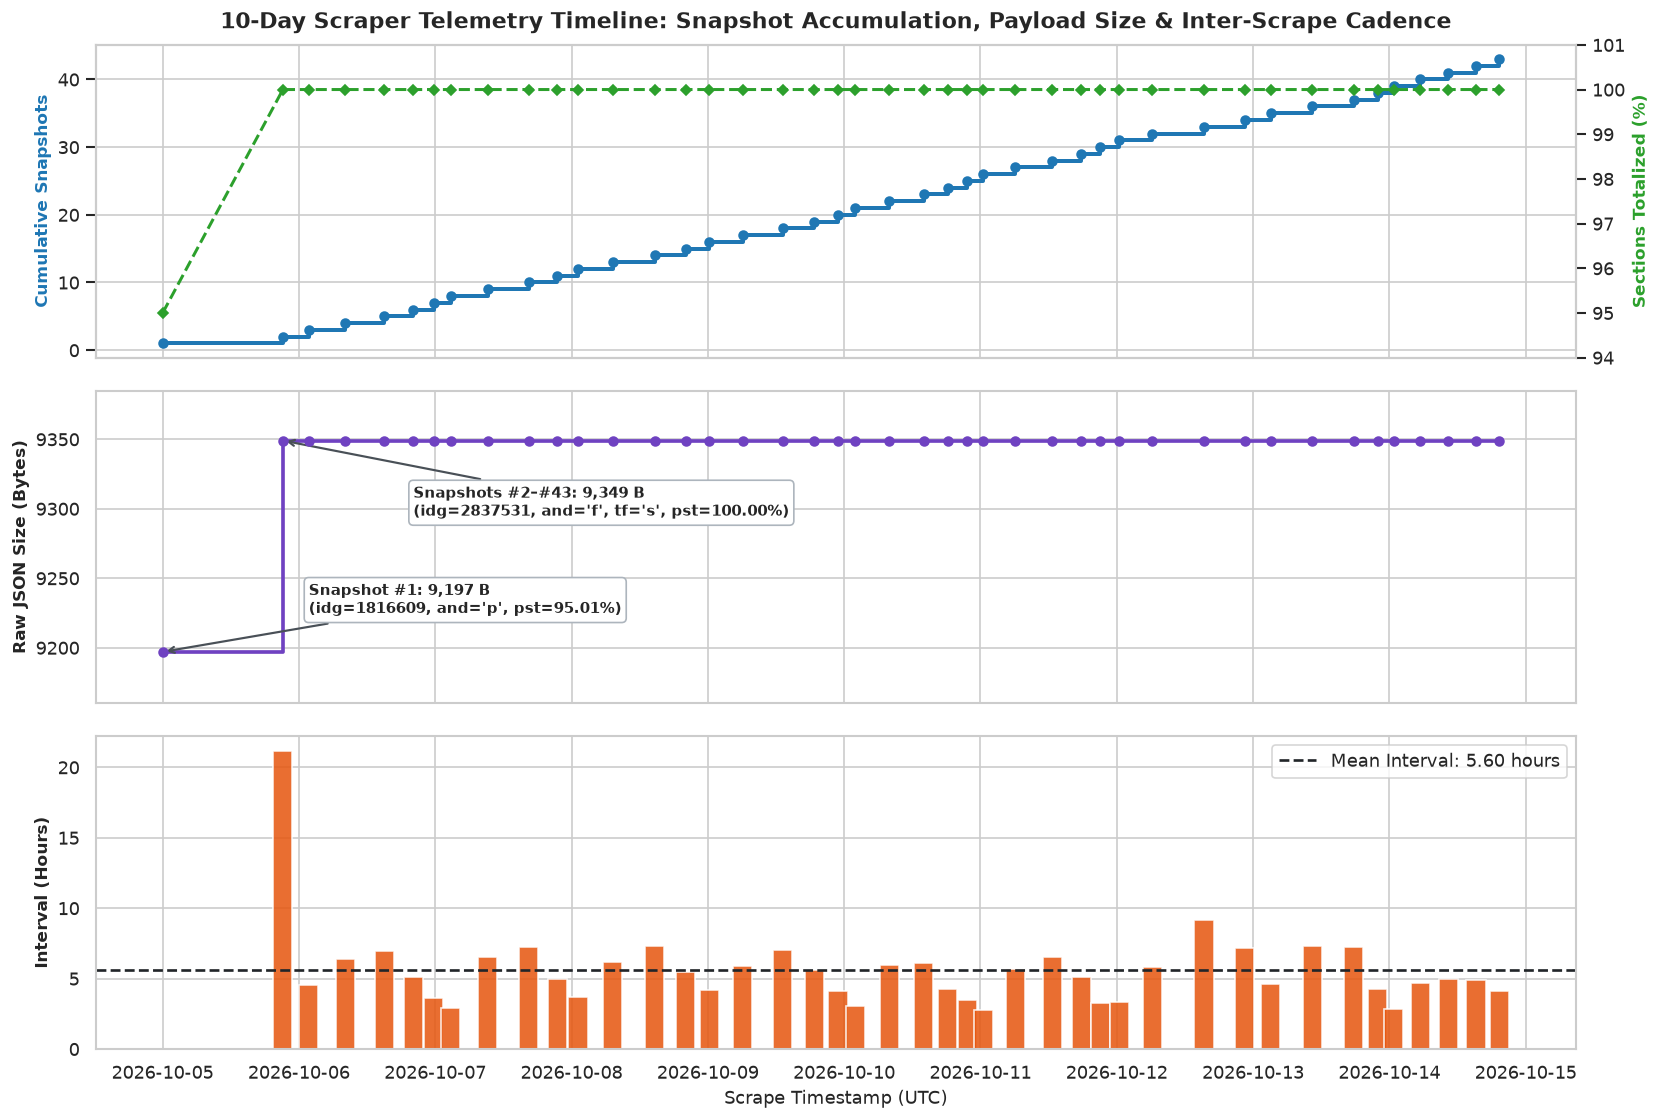

In [2]:
# Graph 1: 3-Panel Operational Timeline Across All 43 Snapshots (Oct 5 - Oct 14, 2026)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 9.5), sharex=True)

# Panel 1: Cumulative Snapshots & Totalized Percentage
ax1.step(df_ts["scraped_at_utc"], df_ts["snapshot_idx"], where="post", color="#1f77b4", linewidth=2.4, label="Cumulative Snapshots (#1 to #43)")
ax1.scatter(df_ts["scraped_at_utc"], df_ts["snapshot_idx"], color="#1f77b4", s=28, zorder=4)
ax1.set_ylabel("Cumulative Snapshots", fontsize=10, color="#1f77b4", fontweight="bold")
ax1.set_title("10-Day Scraper Telemetry Timeline: Snapshot Accumulation, Payload Size & Inter-Scrape Cadence", fontsize=13, fontweight="bold", pad=10)

ax1_twin = ax1.twinx()
ax1_twin.plot(df_ts["scraped_at_utc"], df_ts["pst_pct"], color="#2ca02c", linestyle="--", marker="D", markersize=4, linewidth=1.8, label="Sections Totalized (%)")
ax1_twin.set_ylabel("Sections Totalized (%)", fontsize=10, color="#2ca02c", fontweight="bold")
ax1_twin.set_ylim(94, 101)
ax1_twin.grid(False)

# Panel 2: Payload Byte Size & TSE Generation ID (idg) Transition
ax2.step(df_ts["scraped_at_utc"], df_ts["source_bytes"], where="post", color="#6f42c1", linewidth=2.2)
ax2.scatter(df_ts["scraped_at_utc"], df_ts["source_bytes"], color="#6f42c1", s=28, zorder=4)
ax2.annotate("Snapshot #1: 9,197 B\n(idg=1816609, and='p', pst=95.01%)",
             xy=(df_ts.loc[0, "scraped_at_utc"], 9197),
             xytext=(df_ts.loc[2, "scraped_at_utc"], 9225),
             arrowprops={"arrowstyle": "->", "color": "#495057", "lw": 1.3},
             fontsize=9, fontweight="bold", bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#adb5bd"})
ax2.annotate("Snapshots #2–#43: 9,349 B\n(idg=2837531, and='f', tf='s', pst=100.00%)",
             xy=(df_ts.loc[1, "scraped_at_utc"], 9349),
             xytext=(df_ts.loc[5, "scraped_at_utc"], 9295),
             arrowprops={"arrowstyle": "->", "color": "#495057", "lw": 1.3},
             fontsize=9, fontweight="bold", bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#adb5bd"})
ax2.set_ylabel("Raw JSON Size (Bytes)", fontsize=10, fontweight="bold")
ax2.set_ylim(9160, 9385)

# Panel 3: Inter-Snapshot Interval (Hours)
ax3.bar(df_ts["scraped_at_utc"].iloc[1:], df_ts["interval_hours"].iloc[1:], width=0.14, color="#e6550d", alpha=0.85, edgecolor="white")
mean_int = df_ts["interval_hours"].mean()
ax3.axhline(mean_int, color="#212529", linestyle="--", linewidth=1.6, label=f"Mean Interval: {mean_int:.2f} hours")
ax3.set_ylabel("Interval (Hours)", fontsize=10, fontweight="bold")
ax3.set_xlabel("Scrape Timestamp (UTC)", fontsize=10.5)
ax3.legend(loc="upper right", frameon=True)
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

plt.tight_layout()
plt.show()

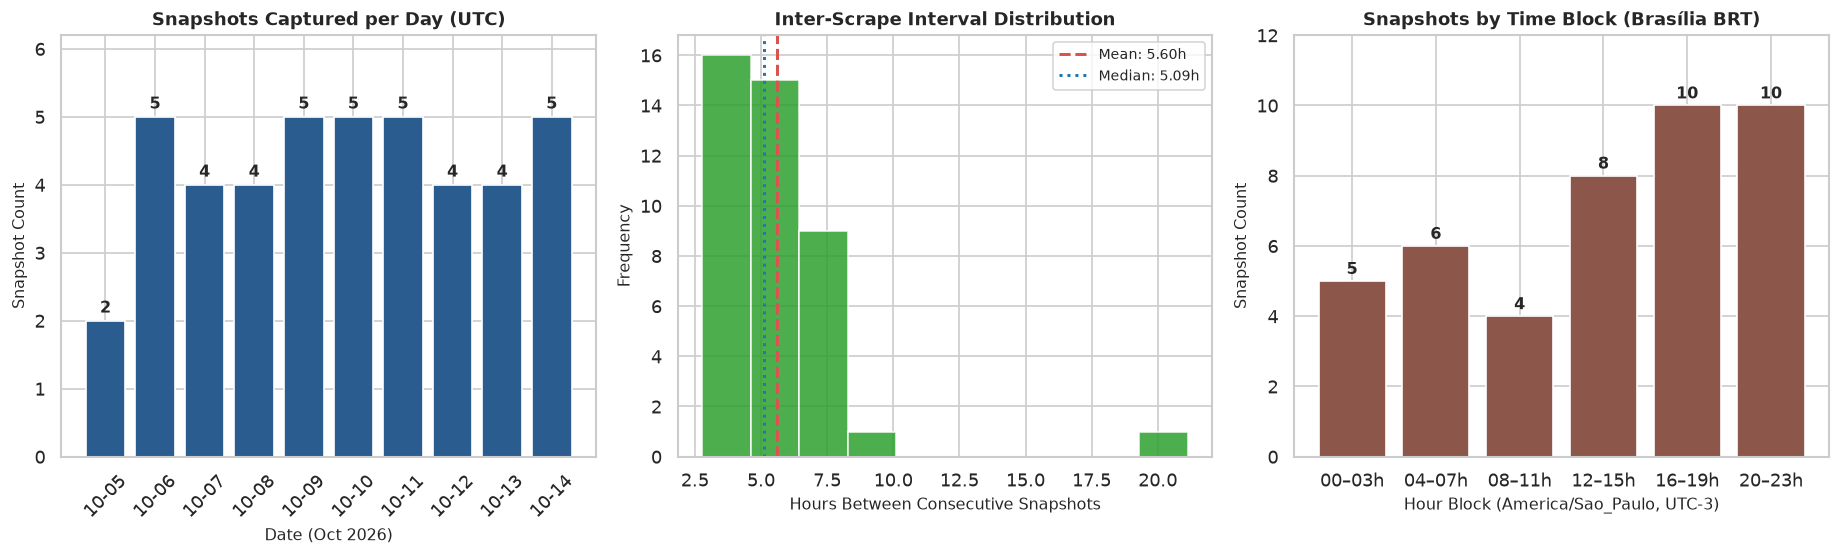

In [3]:
# Graph 2: Daily Snapshot Count, Interval Distribution & Time-of-Day Profile (Brasília Time)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.5, 4.8))

# Left: Snapshots per UTC Date
daily_counts = df_ts.groupby("scrape_date_utc").size()
ax1.bar([d.strftime("%m-%d") for d in daily_counts.index], daily_counts.values, color="#2b5c8f", edgecolor="white")
for i, v_cnt in enumerate(daily_counts.values):
    ax1.text(i, v_cnt + 0.12, str(v_cnt), ha="center", fontweight="bold", fontsize=9.5)
ax1.set_ylim(0, 6.2)
ax1.set_title("Snapshots Captured per Day (UTC)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Date (Oct 2026)", fontsize=9.5)
ax1.set_ylabel("Snapshot Count", fontsize=9.5)
ax1.tick_params(axis="x", rotation=45)

# Middle: Histogram of Inter-Scrape Intervals (Hours)
intervals = df_ts["interval_hours"].dropna()
ax2.hist(intervals, bins=10, color="#2ca02c", edgecolor="white", alpha=0.85)
ax2.axvline(intervals.mean(), color="#d9534f", linestyle="--", linewidth=1.8, label=f"Mean: {intervals.mean():.2f}h")
ax2.axvline(intervals.median(), color="#1f77b4", linestyle=":", linewidth=1.8, label=f"Median: {intervals.median():.2f}h")
ax2.set_title("Inter-Scrape Interval Distribution", fontsize=11, fontweight="bold")
ax2.set_xlabel("Hours Between Consecutive Snapshots", fontsize=9.5)
ax2.set_ylabel("Frequency", fontsize=9.5)
ax2.legend(frameon=True, fontsize=8.5)

# Right: Scrape Frequency by 4-Hour Time Block in Brasília Time (America/Sao_Paulo)
bins_brt = [0, 4, 8, 12, 16, 20, 24]
labels_brt = ["00–03h", "04–07h", "08–11h", "12–15h", "16–19h", "20–23h"]
brt_blocks = pd.cut(df_ts["brt_hour"], bins=bins_brt, right=False, labels=labels_brt).value_counts().reindex(labels_brt)
ax3.bar(brt_blocks.index, brt_blocks.values, color="#8c564b", edgecolor="white")
for i, v_cnt in enumerate(brt_blocks.values):
    ax3.text(i, v_cnt + 0.2, str(v_cnt), ha="center", fontweight="bold", fontsize=9.5)
ax3.set_ylim(0, 12)
ax3.set_title("Snapshots by Time Block (Brasília BRT)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Hour Block (America/Sao_Paulo, UTC-3)", fontsize=9.5)
ax3.set_ylabel("Snapshot Count", fontsize=9.5)

plt.tight_layout()
plt.show()

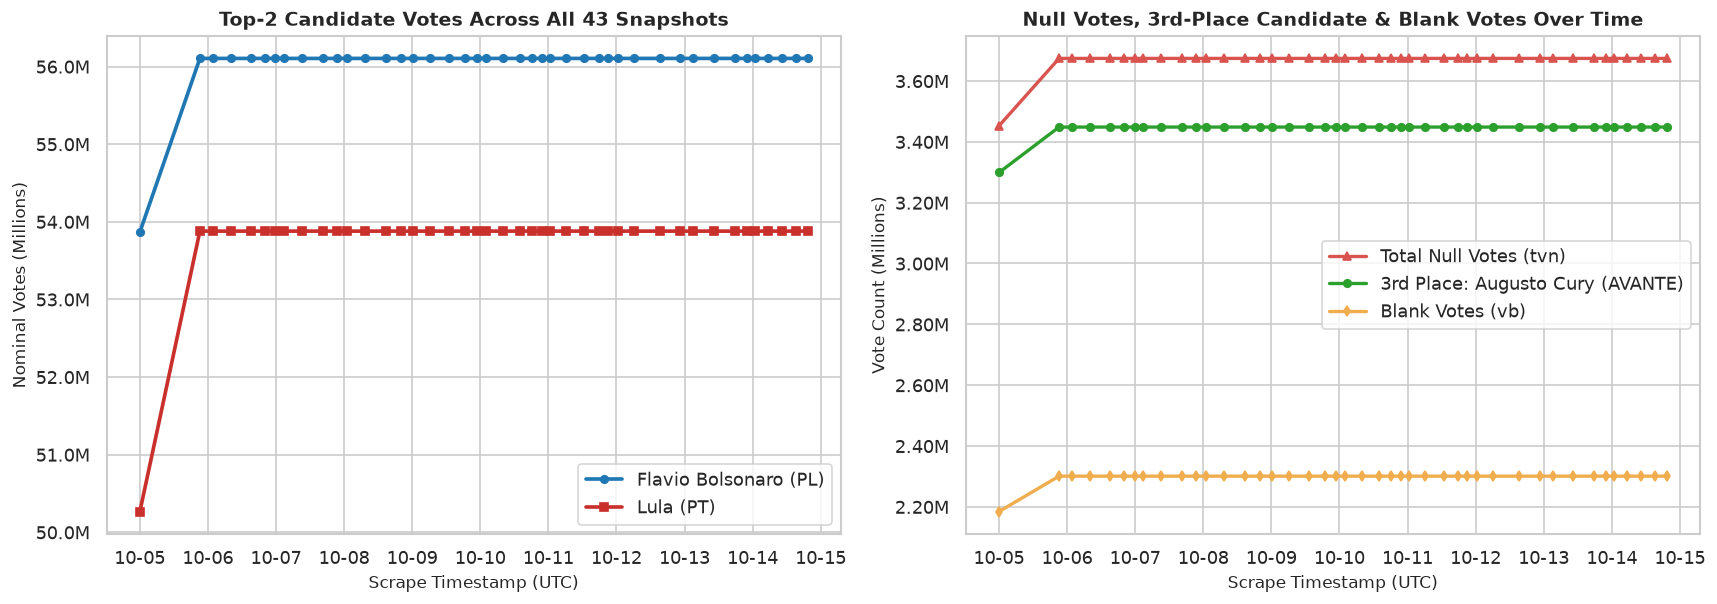

In [4]:
# Graph 3: Time-Series of Leading Candidates & Aggregate Vote Categories Across All 43 Snapshots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Left: Flavio Bolsonaro vs Lula Votes Across Snapshots #1 to #43
ax1.plot(df_ts["scraped_at_utc"], df_ts["flavio_votes"] / 1e6, marker="o", markersize=4.5, linewidth=2.2, color="#1f77b4", label="Flavio Bolsonaro (PL)")
ax1.plot(df_ts["scraped_at_utc"], df_ts["lula_votes"] / 1e6, marker="s", markersize=4.5, linewidth=2.2, color="#c9302c", label="Lula (PT)")
ax1.set_title("Top-2 Candidate Votes Across All 43 Snapshots", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Scrape Timestamp (UTC)", fontsize=10)
ax1.set_ylabel("Nominal Votes (Millions)", fontsize=10)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:.1f}M"))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax1.legend(loc="lower right", frameon=True)

# Right: 3rd Place (Augusto Cury), Null Votes (tvn), and Blank Votes (vb) Over Time
ax2.plot(df_ts["scraped_at_utc"], df_ts["null_votes"] / 1e6, marker="^", markersize=4.5, linewidth=2.0, color="#d9534f", label="Total Null Votes (tvn)")
ax2.plot(df_ts["scraped_at_utc"], df_ts["cury_votes"] / 1e6, marker="o", markersize=4.5, linewidth=2.0, color="#2ca02c", label="3rd Place: Augusto Cury (AVANTE)")
ax2.plot(df_ts["scraped_at_utc"], df_ts["blank_votes"] / 1e6, marker="d", markersize=4.5, linewidth=2.0, color="#f0ad4e", label="Blank Votes (vb)")
ax2.set_title("Null Votes, 3rd-Place Candidate & Blank Votes Over Time", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Scrape Timestamp (UTC)", fontsize=10)
ax2.set_ylabel("Vote Count (Millions)", fontsize=10)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:.2f}M"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax2.legend(loc="center right", frameon=True)

plt.tight_layout()
plt.show()